In [1]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio
import csv
import warnings
warnings.filterwarnings('ignore')

In [2]:
paths = []
labels = []
for dirname, _, filenames in os.walk("C:/Users/Tharunraj_S/Desktop/Major project/codes/TESS Toronto emotional speech set data"):
    for filename in filenames:
        paths.append(os.path.join(dirname, filename))
        label = filename.split('_')[-1]
        label = label.split('.')[0]
        labels.append(label.lower())
    if len(paths) == 2800:
        break
print('Dataset is Loaded')

Dataset is Loaded


In [3]:
## Create a dataframe
df = pd.DataFrame()
df['speech'] = paths
df['label'] = labels
df.head()

,speech,label
0,C:/Users/Tharunraj_S/Desktop/Major project/cod...,angry
1,C:/Users/Tharunraj_S/Desktop/Major project/cod...,angry
2,C:/Users/Tharunraj_S/Desktop/Major project/cod...,angry
3,C:/Users/Tharunraj_S/Desktop/Major project/cod...,angry
4,C:/Users/Tharunraj_S/Desktop/Major project/cod...,angry


In [4]:
def extract_mfcc(filename):
    y, sr = librosa.load(filename, duration=3, offset=0.5)
    mfcc = np.mean(librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40).T, axis=0)
    return mfcc

In [5]:
X_mfcc = df['speech'].apply(lambda x: extract_mfcc(x))

In [6]:
X = [x for x in X_mfcc]
X = np.array(X)
## input split
X = np.expand_dims(X, -1)
X.shape

(2800, 40, 1)

In [7]:
from sklearn.preprocessing import OneHotEncoder
enc = OneHotEncoder()
y = enc.fit_transform(df[['label']])
y = y.toarray()

In [8]:
y.shape

(2800, 7)

In [9]:
class_labels = df['label'].unique().tolist()

In [10]:
class_labels

['angry', 'disgust', 'fear', 'happy', 'neutral', 'ps', 'sad']

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


In [12]:
# Define the LSTM model in PyTorch
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, num_classes):
        super(LSTMModel, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc1 = nn.Linear(hidden_size, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
        
        out, _ = self.lstm(x, (h0, c0))
        out = self.relu(out[:, -1, :])  # Consider only the output of the last time step
        out = self.fc1(out)
        out = self.relu(out)
        out = self.fc2(out)
        out = self.relu(out)
        out = self.fc3(out)
        out = self.softmax(out)
        return out


In [13]:
# Define your custom dataset
class SpeechDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [14]:
from sklearn.model_selection import train_test_split
import numpy as np

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Convert to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)


In [15]:
train_dataset = SpeechDataset(X_train_tensor, y_train_tensor)
val_dataset = SpeechDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader= DataLoader(val_dataset, batch_size=64, shuffle=True)

In [16]:
# Define device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Initialize the model
input_size = 1  
hidden_size = 256
num_layers = 1
num_classes = 7
model = LSTMModel(input_size, hidden_size, num_layers, num_classes).to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [17]:
import numpy as np

# Function to calculate evaluation metrics
def calculate_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    # Convert from one-hot encoding to class labels if needed
    if len(y_true.shape) > 1:
        y_true = np.argmax(y_true, axis=1)
    if len(y_pred.shape) > 1:
        y_pred = np.argmax(y_pred, axis=1)
    
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    return accuracy, precision, recall, f1


# Validation function
def validate(model, val_loader, criterion, device):
    model.eval()
    val_loss = 0.0
    y_true = []
    y_pred = []
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)  # Convert one-hot to class labels
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    val_loss /= len(val_loader.dataset)
    accuracy, precision, recall, f1 = calculate_metrics(y_true, y_pred)
    
    return val_loss, accuracy, precision, recall, f1


In [18]:
def plot_graphs(num_epochs,
                train_losses,
                val_losses,
                train_accuracies,
                val_accuracies,
                train_precisions,
                val_precisions,
                train_recalls,
                val_recalls,
                train_f1s,
                val_f1s):
    
    epochs_dir = str(num_epochs)+" Epochs"
    
    # Plotting the metrics
    epochs = list(range(num_epochs))

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_losses, label='Training Loss')
    plt.plot(epochs, val_losses, label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.savefig(os.path.join(epochs_dir, 'loss_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_accuracies, label='Training Accuracy')
    plt.plot(epochs, val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.legend()
    plt.savefig(os.path.join(epochs_dir, 'accuracy_plot.png'))
    plt.show()
    plt.close()


    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_precisions, label='Training Precision')
    plt.plot(epochs, val_precisions, label='Validation Precision')
    plt.xlabel('Epochs')
    plt.ylabel('Precision')
    plt.title('Training and Validation Precision')
    plt.legend()
    plt.savefig(os.path.join(epochs_dir, 'precision_plot.png'))
    plt.show()
    plt.close()
    
    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_recalls, label='Training Recall')
    plt.plot(epochs, val_recalls, label='Validation Recall')
    plt.xlabel('Epochs')
    plt.ylabel('Recall')
    plt.title('Training and Validation Recall')
    plt.legend()
    plt.savefig(os.path.join(epochs_dir, 'recall_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_f1s, label='Training F1-score')
    plt.plot(epochs, val_f1s, label='Validation F1-score')
    plt.xlabel('Epochs')
    plt.ylabel('F1-score')
    plt.title('Training and Validation F1-score')
    plt.legend()
    plt.savefig(os.path.join(epochs_dir, 'f1Score_plot.png'))
    plt.show()
    plt.close()

    return "Model Training and Evaluation Successfully completed"


In [19]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

def generate_confusion_matrix(model, test_loader, device):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())
    
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')        
    print(f"\nAccuracy : {accuracy}\nPrecision : {precision}\nRecall : {recall}\nF1-Score : {f1}")

    conf_matrix = confusion_matrix(y_true, y_pred)
    return conf_matrix

def plot_confusion_matrix(conf_matrix, class_labels,epochs_dir):
    plt.figure(figsize=(10, 8))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.title('Confusion Matrix')
    plt.xticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.savefig(os.path.join(epochs_dir, 'Confusion Matrix.png'))
    plt.show()


In [20]:
def train_model():
    
    # Initialize variables to store best validation metrics and corresponding model state
    best_val_loss = float('inf')
    best_model_state = None
    
    # Training loop    
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []
    train_precisions = []
    val_precisions = []
    train_recalls = []
    val_recalls = []
    train_f1s = []
    val_f1s = []
    num_epochs =int(input("Enter no. of epochs "))
    
    # Create a directory with the name as the number of epochs
    epochs_dir = str(num_epochs)+" Epochs"
    if not os.path.exists(epochs_dir):
        os.makedirs(epochs_dir)
        
    with open(os.path.join(epochs_dir,'metrics.csv'), mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(['Epoch', 'Training Loss', 'Training Accuracy','Training Precision', 'Training Recall', 'Training F1-Score'
                         , 'Validation Loss', 'Validation Accuracy','Validatio Precision', 'Validatio Recall', 'Validatio F1-Score'])
        
        for epoch in range(num_epochs):
            model.train()
            running_loss = 0.0

            for inputs, labels in train_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                running_loss += loss.item() * inputs.size(0)

            # Calculate training loss
            train_loss = running_loss / len(train_loader.dataset)
            train_losses.append(train_loss)

            # Calculate training metrics
            y_true_train = []
            y_pred_train = []
            with torch.no_grad():
                for inputs, labels in train_loader:
                    inputs = inputs.to(device)
                    labels = labels.to(device)
                    outputs = model(inputs)
                    _, predicted = torch.max(outputs, 1)
                    y_true_train.extend(labels.cpu().numpy())
                    y_pred_train.extend(predicted.cpu().numpy())

            train_accuracy, train_precision, train_recall, train_f1 = calculate_metrics(y_true_train, y_pred_train)
            train_accuracies.append(train_accuracy)
            train_precisions.append(train_precision)
            train_recalls.append(train_recall)
            train_f1s.append(train_f1)

            # Validate the model
            val_loss, val_accuracy, val_precision, val_recall, val_f1 = validate(model, val_loader, criterion, device)
            val_losses.append(val_loss)
            val_accuracies.append(val_accuracy)
            val_precisions.append(val_precision)
            val_recalls.append(val_recall)
            val_f1s.append(val_f1)

            # Write metrics to CSV
            writer.writerow([epoch+1, train_loss, train_accuracy, train_precision, train_recall, train_f1,
                             val_loss, val_accuracy, val_precision, val_recall, val_f1])


            print(f'Epoch [{epoch+1}/{num_epochs}],\n'
                  f'Training Loss: {train_loss:.4f}, Training Accuracy: {train_accuracy:.4f}, '
                  f'Training Precision:{train_precision:.4f},Training Recall:{train_recall:.4f},Training F1-Score:{train_f1:.4f}\n'
                  f'Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.4f}, '
                  f'Validation Precision:{val_precision:.4f},Validation Recall:{val_recall:.4f},Validation F1-Score:{val_f1:.4f}'
                  )
            # Save the model
            torch.save(model.state_dict(), os.path.join(epochs_dir, 'LSTM_model_(last).pth'))
            
            # Save the model if it has the best validation loss so far
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_model_state = model.state_dict()
                torch.save(model.state_dict(), os.path.join(epochs_dir, 'LSTM_model_(best).pth'))
   
    # Load the best model state
    model.load_state_dict(best_model_state)
    conf_matrix = generate_confusion_matrix(model, val_loader, device)
    plot_confusion_matrix(conf_matrix, class_labels,epochs_dir)  
    
            
    return plot_graphs(num_epochs,train_losses,val_losses,train_accuracies,val_accuracies,train_precisions,val_precisions,train_recalls,val_recalls,train_f1s,val_f1s)
        

## Training and Validation 50 epochs

Enter no. of epochs 50
Epoch [1/50],
Training Loss: 1.8552, Training Accuracy: 0.5241, Training Precision:0.4644,Training Recall:0.5241,Training F1-Score:0.3974
Validation Loss: 1.6821, Validation Accuracy: 0.4821, Validation Precision:0.2979,Validation Recall:0.4821,Validation F1-Score:0.3616
Epoch [2/50],
Training Loss: 1.5741, Training Accuracy: 0.7076, Training Precision:0.6218,Training Recall:0.7076,Training F1-Score:0.6518
Validation Loss: 1.5025, Validation Accuracy: 0.6839, Validation Precision:0.5964,Validation Recall:0.6839,Validation F1-Score:0.6269
Epoch [3/50],
Training Loss: 1.4547, Training Accuracy: 0.7719, Training Precision:0.6923,Training Recall:0.7719,Training F1-Score:0.7227
Validation Loss: 1.4062, Validation Accuracy: 0.7643, Validation Precision:0.6773,Validation Recall:0.7643,Validation F1-Score:0.7102
Epoch [4/50],
Training Loss: 1.4187, Training Accuracy: 0.7670, Training Precision:0.6854,Training Recall:0.7670,Training F1-Score:0.7159
Validation Loss: 1.4067

Epoch [31/50],
Training Loss: 1.3645, Training Accuracy: 0.7487, Training Precision:0.6766,Training Recall:0.7487,Training F1-Score:0.6909
Validation Loss: 1.4206, Validation Accuracy: 0.7446, Validation Precision:0.6582,Validation Recall:0.7446,Validation F1-Score:0.6825
Epoch [32/50],
Training Loss: 1.3787, Training Accuracy: 0.8317, Training Precision:0.7215,Training Recall:0.8317,Training F1-Score:0.7713
Validation Loss: 1.3454, Validation Accuracy: 0.8214, Validation Precision:0.6995,Validation Recall:0.8214,Validation F1-Score:0.7544
Epoch [33/50],
Training Loss: 1.3419, Training Accuracy: 0.8201, Training Precision:0.7298,Training Recall:0.8201,Training F1-Score:0.7649
Validation Loss: 1.3460, Validation Accuracy: 0.8214, Validation Precision:0.7145,Validation Recall:0.8214,Validation F1-Score:0.7584
Epoch [34/50],
Training Loss: 1.3243, Training Accuracy: 0.8754, Training Precision:0.8670,Training Recall:0.8754,Training F1-Score:0.8597
Validation Loss: 1.2952, Validation Accura

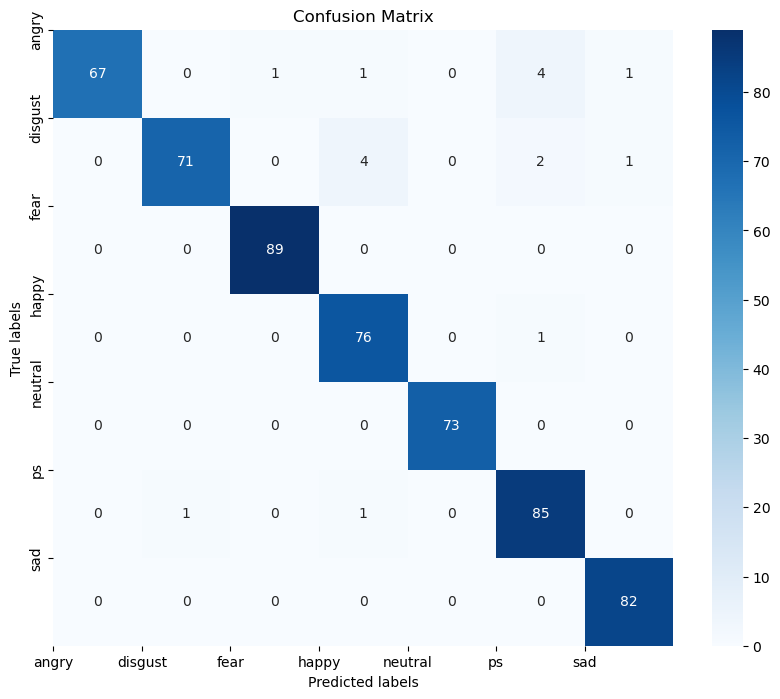

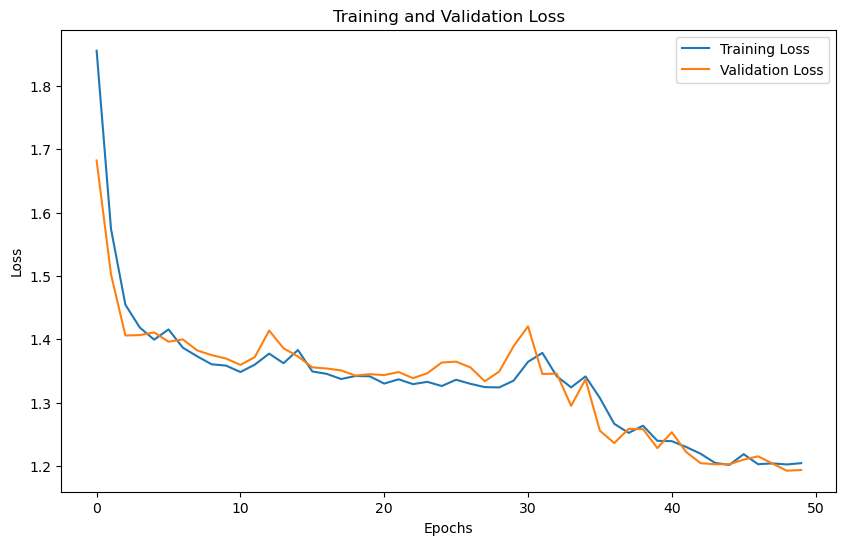

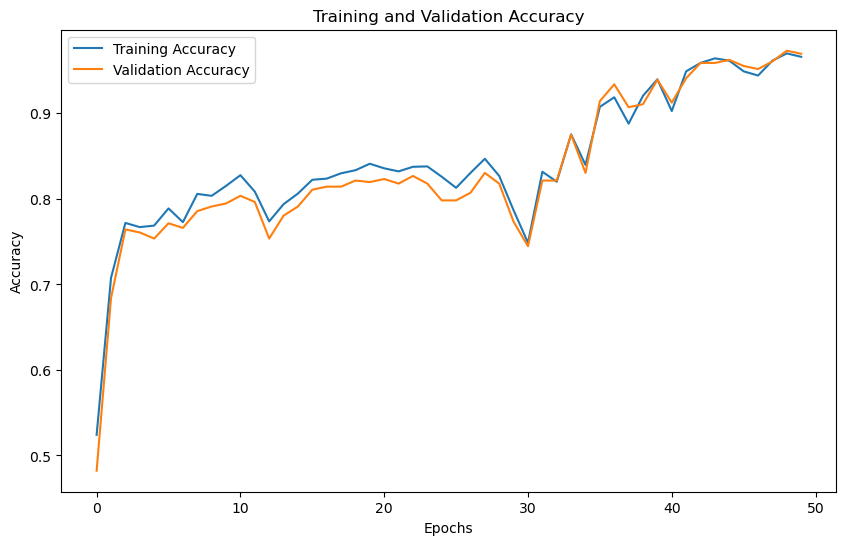

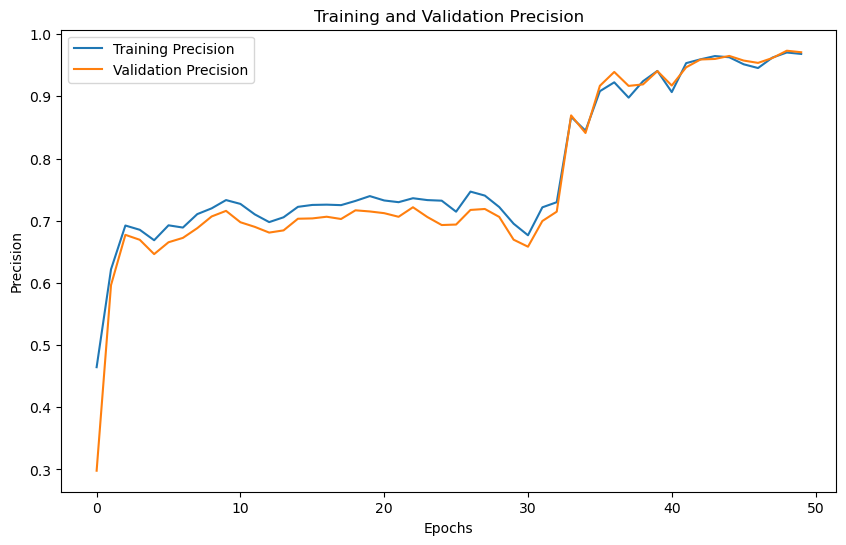

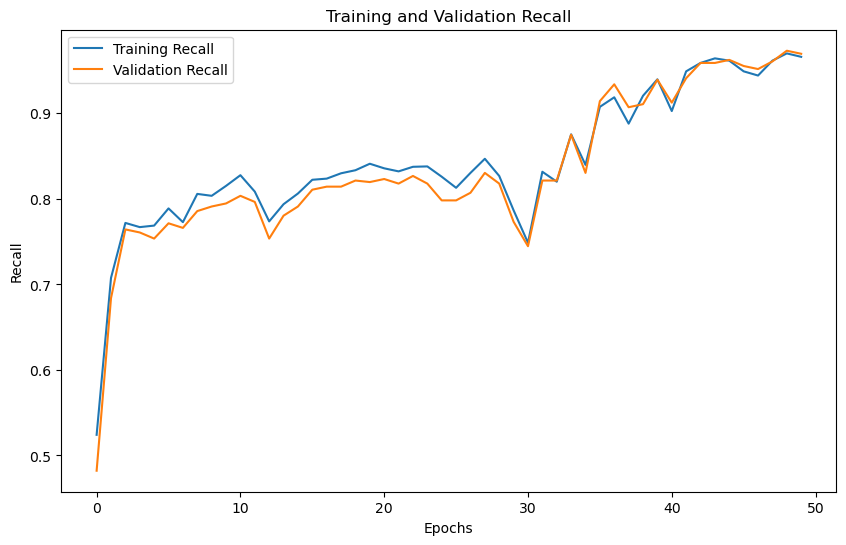

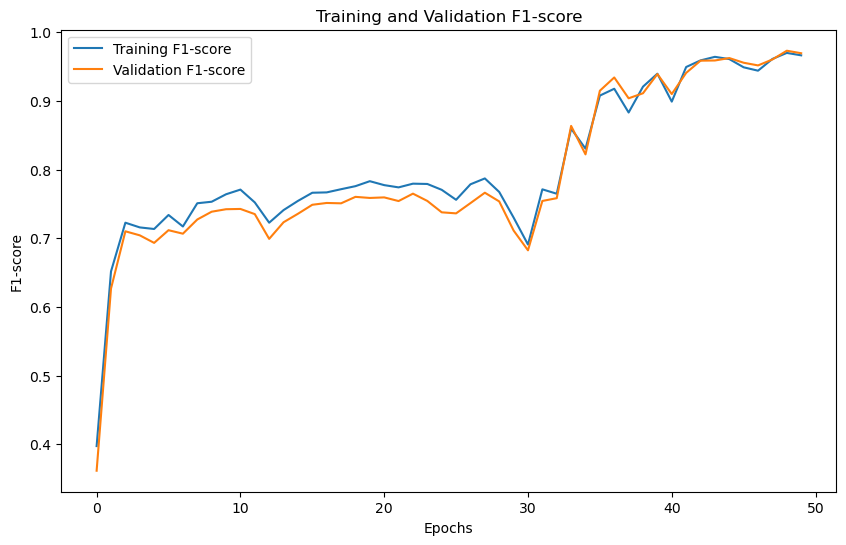

'Model Training and Evaluation Successfully completed'

In [21]:
train_model()

## Training and Validation 100 epochs

Enter no. of epochs 100
Epoch [1/100],
Training Loss: 1.8406, Training Accuracy: 0.5554, Training Precision:0.3760,Training Recall:0.5554,Training F1-Score:0.4346
Validation Loss: 1.6104, Validation Accuracy: 0.5518, Validation Precision:0.3774,Validation Recall:0.5518,Validation F1-Score:0.4330
Epoch [2/100],
Training Loss: 1.5312, Training Accuracy: 0.7290, Training Precision:0.6901,Training Recall:0.7290,Training F1-Score:0.6902
Validation Loss: 1.4468, Validation Accuracy: 0.7268, Validation Precision:0.6807,Validation Recall:0.7268,Validation F1-Score:0.6844
Epoch [3/100],
Training Loss: 1.4330, Training Accuracy: 0.7348, Training Precision:0.7682,Training Recall:0.7348,Training F1-Score:0.6892
Validation Loss: 1.4277, Validation Accuracy: 0.7429, Validation Precision:0.6740,Validation Recall:0.7429,Validation F1-Score:0.6915
Epoch [4/100],
Training Loss: 1.3897, Training Accuracy: 0.8187, Training Precision:0.8227,Training Recall:0.8187,Training F1-Score:0.8103
Validation Loss: 1

Epoch [31/100],
Training Loss: 1.2328, Training Accuracy: 0.9491, Training Precision:0.9500,Training Recall:0.9491,Training F1-Score:0.9491
Validation Loss: 1.2262, Validation Accuracy: 0.9393, Validation Precision:0.9415,Validation Recall:0.9393,Validation F1-Score:0.9395
Epoch [32/100],
Training Loss: 1.2210, Training Accuracy: 0.9554, Training Precision:0.9565,Training Recall:0.9554,Training F1-Score:0.9552
Validation Loss: 1.2074, Validation Accuracy: 0.9571, Validation Precision:0.9588,Validation Recall:0.9571,Validation F1-Score:0.9571
Epoch [33/100],
Training Loss: 1.2258, Training Accuracy: 0.9366, Training Precision:0.9391,Training Recall:0.9366,Training F1-Score:0.9367
Validation Loss: 1.2234, Validation Accuracy: 0.9429, Validation Precision:0.9454,Validation Recall:0.9429,Validation F1-Score:0.9430
Epoch [34/100],
Training Loss: 1.2237, Training Accuracy: 0.9563, Training Precision:0.9569,Training Recall:0.9563,Training F1-Score:0.9564
Validation Loss: 1.2062, Validation Ac

Epoch [61/100],
Training Loss: 1.2240, Training Accuracy: 0.9201, Training Precision:0.9269,Training Recall:0.9201,Training F1-Score:0.9198
Validation Loss: 1.2537, Validation Accuracy: 0.9107, Validation Precision:0.9192,Validation Recall:0.9107,Validation F1-Score:0.9100
Epoch [62/100],
Training Loss: 1.2152, Training Accuracy: 0.9674, Training Precision:0.9682,Training Recall:0.9674,Training F1-Score:0.9674
Validation Loss: 1.2062, Validation Accuracy: 0.9607, Validation Precision:0.9626,Validation Recall:0.9607,Validation F1-Score:0.9607
Epoch [63/100],
Training Loss: 1.1940, Training Accuracy: 0.9759, Training Precision:0.9761,Training Recall:0.9759,Training F1-Score:0.9759
Validation Loss: 1.2054, Validation Accuracy: 0.9589, Validation Precision:0.9603,Validation Recall:0.9589,Validation F1-Score:0.9591
Epoch [64/100],
Training Loss: 1.2233, Training Accuracy: 0.9558, Training Precision:0.9592,Training Recall:0.9558,Training F1-Score:0.9562
Validation Loss: 1.2252, Validation Ac

Epoch [91/100],
Training Loss: 1.2047, Training Accuracy: 0.9714, Training Precision:0.9719,Training Recall:0.9714,Training F1-Score:0.9714
Validation Loss: 1.2015, Validation Accuracy: 0.9625, Validation Precision:0.9641,Validation Recall:0.9625,Validation F1-Score:0.9625
Epoch [92/100],
Training Loss: 1.1943, Training Accuracy: 0.9741, Training Precision:0.9748,Training Recall:0.9741,Training F1-Score:0.9740
Validation Loss: 1.1927, Validation Accuracy: 0.9732, Validation Precision:0.9735,Validation Recall:0.9732,Validation F1-Score:0.9731
Epoch [93/100],
Training Loss: 1.1988, Training Accuracy: 0.9723, Training Precision:0.9729,Training Recall:0.9723,Training F1-Score:0.9721
Validation Loss: 1.2064, Validation Accuracy: 0.9589, Validation Precision:0.9621,Validation Recall:0.9589,Validation F1-Score:0.9590
Epoch [94/100],
Training Loss: 1.1898, Training Accuracy: 0.9589, Training Precision:0.9618,Training Recall:0.9589,Training F1-Score:0.9586
Validation Loss: 1.2285, Validation Ac

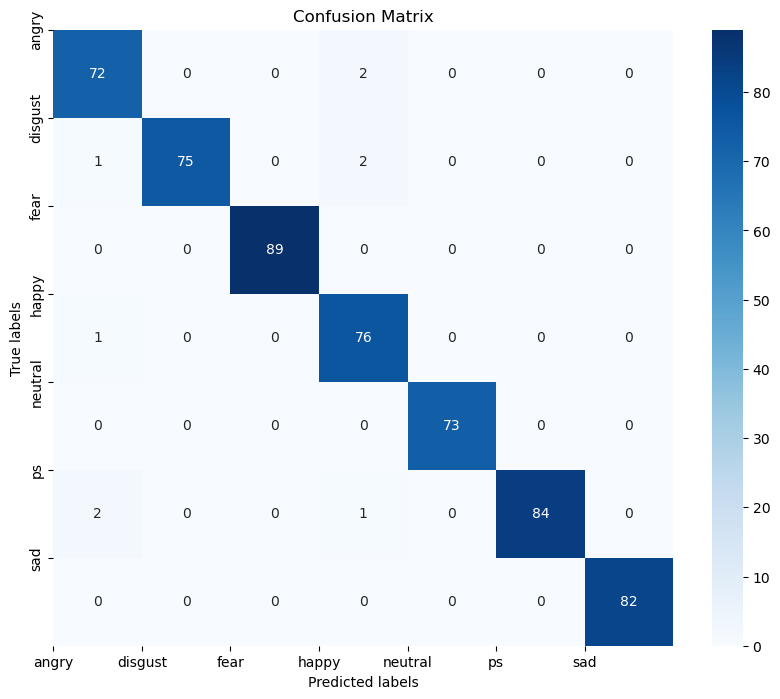

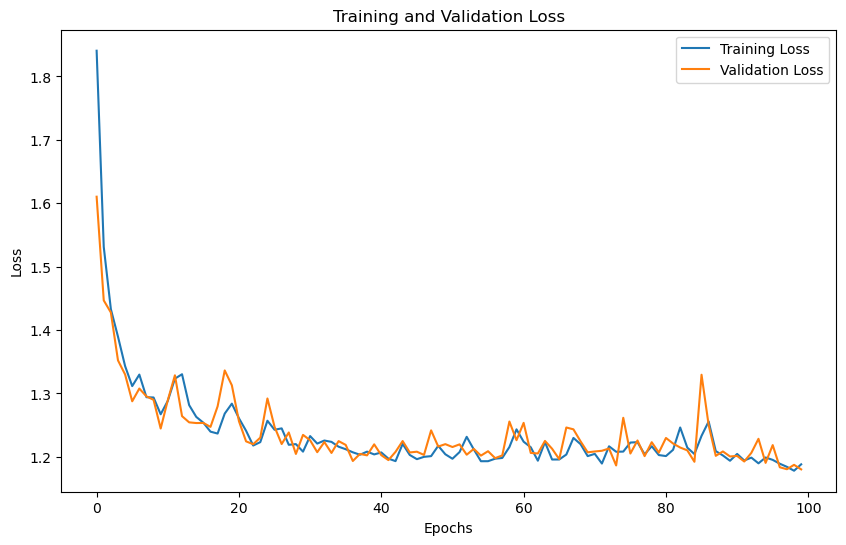

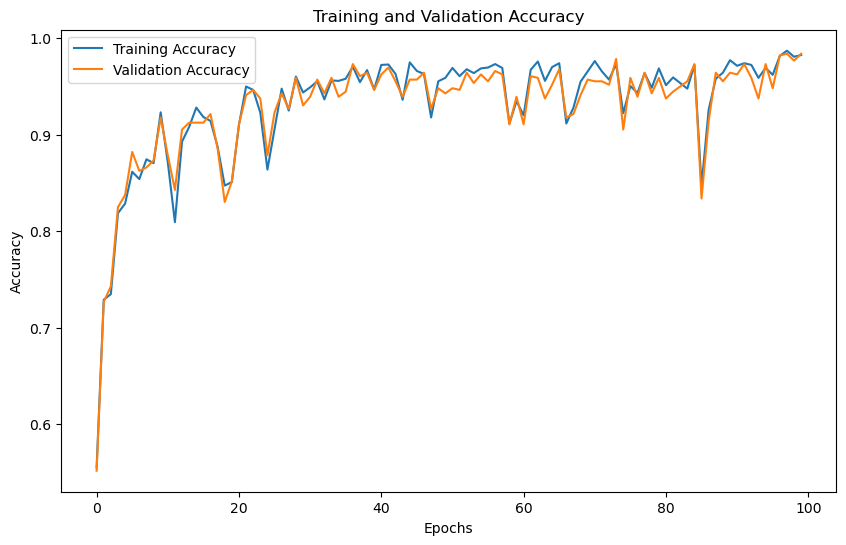

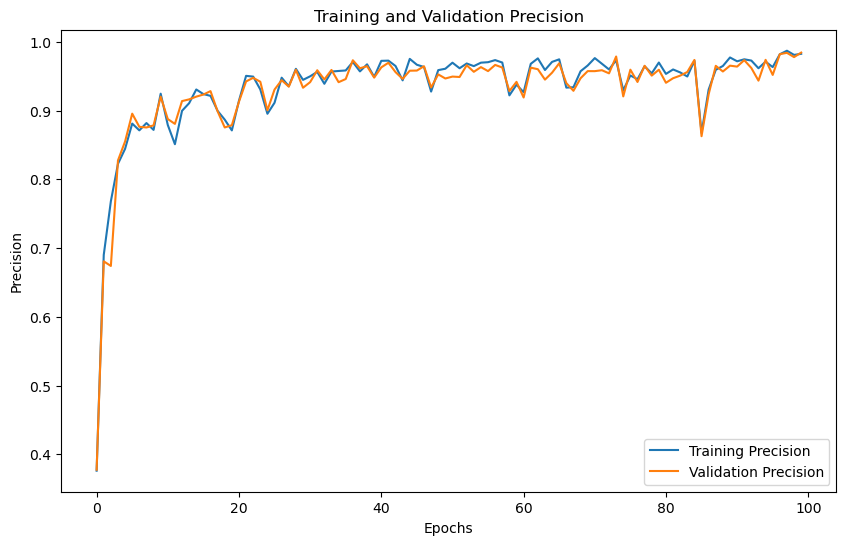

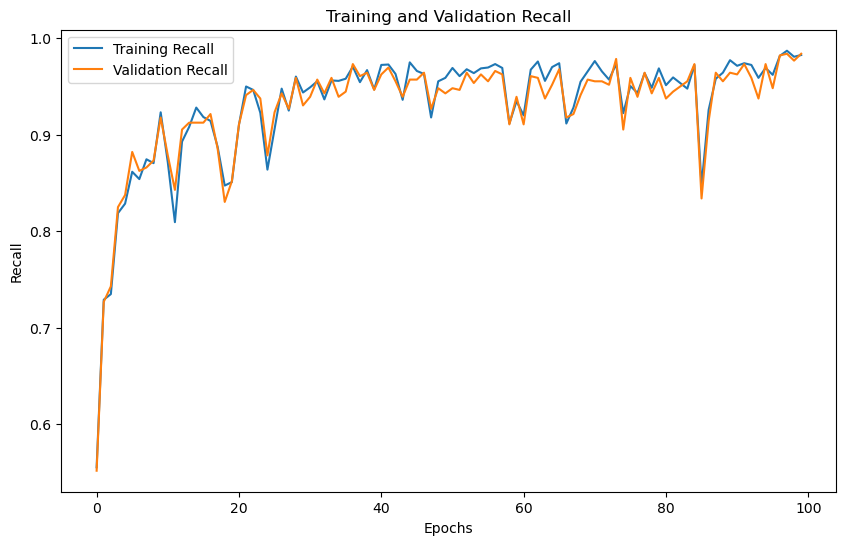

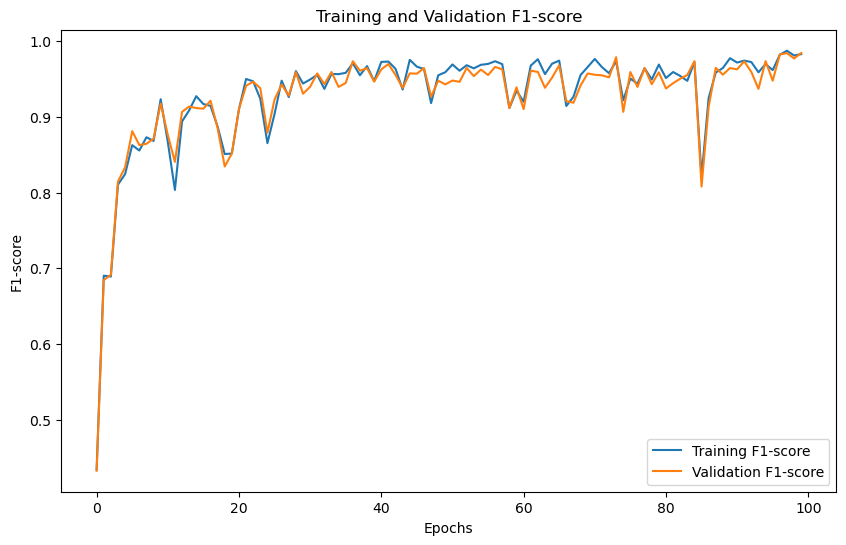

'Model Training and Evaluation Successfully completed'

In [21]:
train_model()

## Training and Validation 150 epochs

Enter no. of epochs 150
Epoch [1/150],
Training Loss: 1.8567, Training Accuracy: 0.5125, Training Precision:0.3849,Training Recall:0.5125,Training F1-Score:0.4300
Validation Loss: 1.7153, Validation Accuracy: 0.5375, Validation Precision:0.3994,Validation Recall:0.5375,Validation F1-Score:0.4447
Epoch [2/150],
Training Loss: 1.5856, Training Accuracy: 0.6540, Training Precision:0.5181,Training Recall:0.6540,Training F1-Score:0.5654
Validation Loss: 1.5287, Validation Accuracy: 0.6429, Validation Precision:0.5162,Validation Recall:0.6429,Validation F1-Score:0.5585
Epoch [3/150],
Training Loss: 1.5085, Training Accuracy: 0.6687, Training Precision:0.5367,Training Recall:0.6687,Training F1-Score:0.5803
Validation Loss: 1.4948, Validation Accuracy: 0.6679, Validation Precision:0.5341,Validation Recall:0.6679,Validation F1-Score:0.5787
Epoch [4/150],
Training Loss: 1.4668, Training Accuracy: 0.7621, Training Precision:0.6579,Training Recall:0.7621,Training F1-Score:0.7036
Validation Loss: 1

Epoch [31/150],
Training Loss: 1.3206, Training Accuracy: 0.8522, Training Precision:0.7391,Training Recall:0.8522,Training F1-Score:0.7901
Validation Loss: 1.3360, Validation Accuracy: 0.8268, Validation Precision:0.7064,Validation Recall:0.8268,Validation F1-Score:0.7600
Epoch [32/150],
Training Loss: 1.3172, Training Accuracy: 0.8424, Training Precision:0.7394,Training Recall:0.8424,Training F1-Score:0.7835
Validation Loss: 1.3449, Validation Accuracy: 0.8179, Validation Precision:0.7129,Validation Recall:0.8179,Validation F1-Score:0.7562
Epoch [33/150],
Training Loss: 1.3134, Training Accuracy: 0.8509, Training Precision:0.7454,Training Recall:0.8509,Training F1-Score:0.7915
Validation Loss: 1.3365, Validation Accuracy: 0.8286, Validation Precision:0.7207,Validation Recall:0.8286,Validation F1-Score:0.7663
Epoch [34/150],
Training Loss: 1.3122, Training Accuracy: 0.8527, Training Precision:0.7399,Training Recall:0.8527,Training F1-Score:0.7906
Validation Loss: 1.3320, Validation Ac

Epoch [61/150],
Training Loss: 1.1908, Training Accuracy: 0.9621, Training Precision:0.9639,Training Recall:0.9621,Training F1-Score:0.9621
Validation Loss: 1.1958, Validation Accuracy: 0.9714, Validation Precision:0.9723,Validation Recall:0.9714,Validation F1-Score:0.9715
Epoch [62/150],
Training Loss: 1.1962, Training Accuracy: 0.9674, Training Precision:0.9679,Training Recall:0.9674,Training F1-Score:0.9670
Validation Loss: 1.2046, Validation Accuracy: 0.9607, Validation Precision:0.9617,Validation Recall:0.9607,Validation F1-Score:0.9605
Epoch [63/150],
Training Loss: 1.1948, Training Accuracy: 0.9656, Training Precision:0.9689,Training Recall:0.9656,Training F1-Score:0.9657
Validation Loss: 1.2209, Validation Accuracy: 0.9429, Validation Precision:0.9476,Validation Recall:0.9429,Validation F1-Score:0.9418
Epoch [64/150],
Training Loss: 1.2096, Training Accuracy: 0.9621, Training Precision:0.9633,Training Recall:0.9621,Training F1-Score:0.9623
Validation Loss: 1.2002, Validation Ac

Epoch [91/150],
Training Loss: 1.1959, Training Accuracy: 0.9643, Training Precision:0.9667,Training Recall:0.9643,Training F1-Score:0.9635
Validation Loss: 1.2002, Validation Accuracy: 0.9625, Validation Precision:0.9650,Validation Recall:0.9625,Validation F1-Score:0.9620
Epoch [92/150],
Training Loss: 1.1948, Training Accuracy: 0.9714, Training Precision:0.9720,Training Recall:0.9714,Training F1-Score:0.9715
Validation Loss: 1.1989, Validation Accuracy: 0.9661, Validation Precision:0.9666,Validation Recall:0.9661,Validation F1-Score:0.9660
Epoch [93/150],
Training Loss: 1.1956, Training Accuracy: 0.9799, Training Precision:0.9803,Training Recall:0.9799,Training F1-Score:0.9800
Validation Loss: 1.1881, Validation Accuracy: 0.9768, Validation Precision:0.9771,Validation Recall:0.9768,Validation F1-Score:0.9768
Epoch [94/150],
Training Loss: 1.1822, Training Accuracy: 0.9857, Training Precision:0.9858,Training Recall:0.9857,Training F1-Score:0.9857
Validation Loss: 1.1847, Validation Ac

Epoch [121/150],
Training Loss: 1.1972, Training Accuracy: 0.9768, Training Precision:0.9772,Training Recall:0.9768,Training F1-Score:0.9767
Validation Loss: 1.1907, Validation Accuracy: 0.9750, Validation Precision:0.9757,Validation Recall:0.9750,Validation F1-Score:0.9751
Epoch [122/150],
Training Loss: 1.1842, Training Accuracy: 0.9915, Training Precision:0.9915,Training Recall:0.9915,Training F1-Score:0.9915
Validation Loss: 1.1847, Validation Accuracy: 0.9804, Validation Precision:0.9805,Validation Recall:0.9804,Validation F1-Score:0.9803
Epoch [123/150],
Training Loss: 1.1771, Training Accuracy: 0.9951, Training Precision:0.9951,Training Recall:0.9951,Training F1-Score:0.9951
Validation Loss: 1.1818, Validation Accuracy: 0.9839, Validation Precision:0.9843,Validation Recall:0.9839,Validation F1-Score:0.9840
Epoch [124/150],
Training Loss: 1.1745, Training Accuracy: 0.9902, Training Precision:0.9903,Training Recall:0.9902,Training F1-Score:0.9901
Validation Loss: 1.1850, Validatio

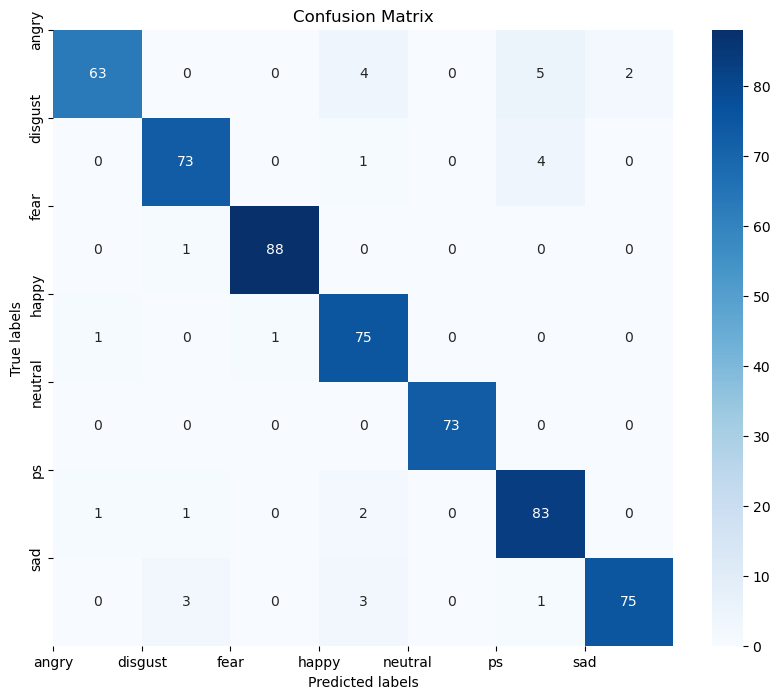

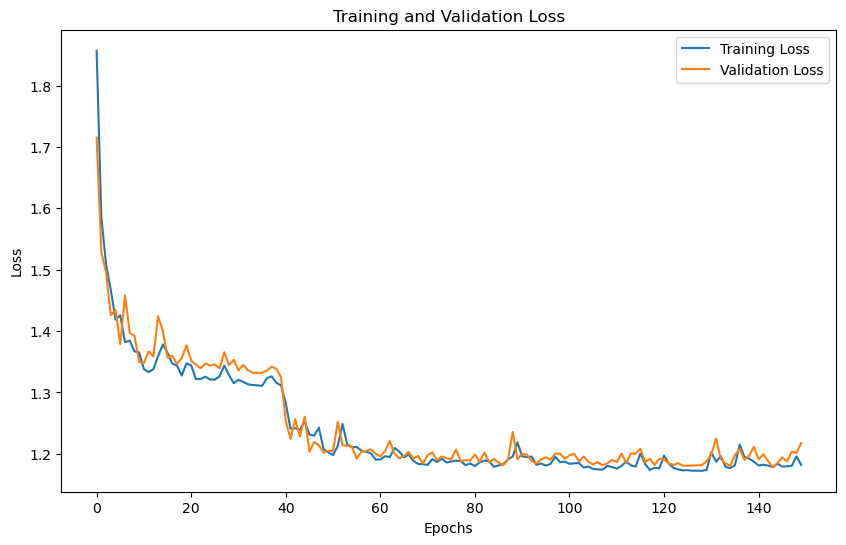

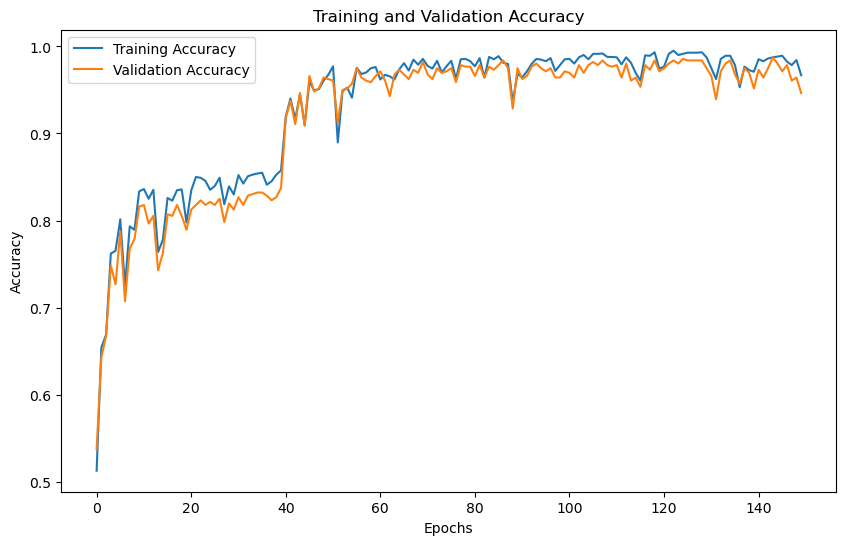

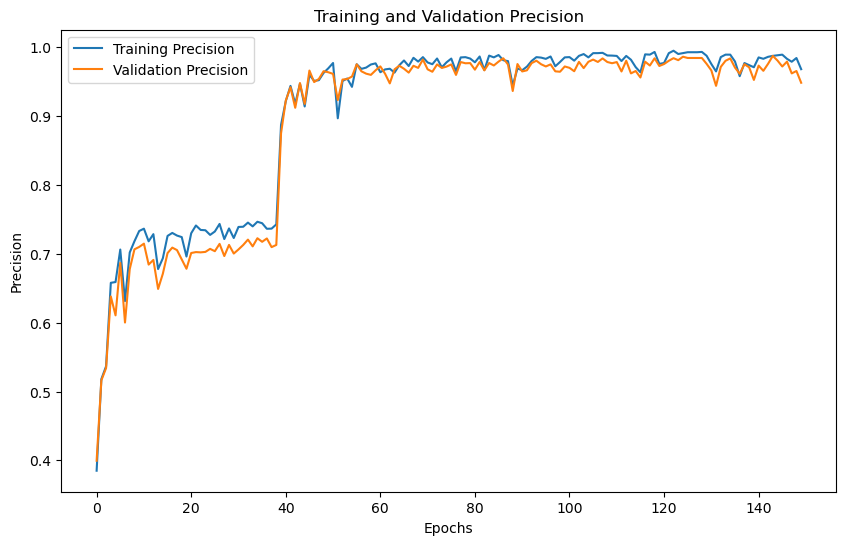

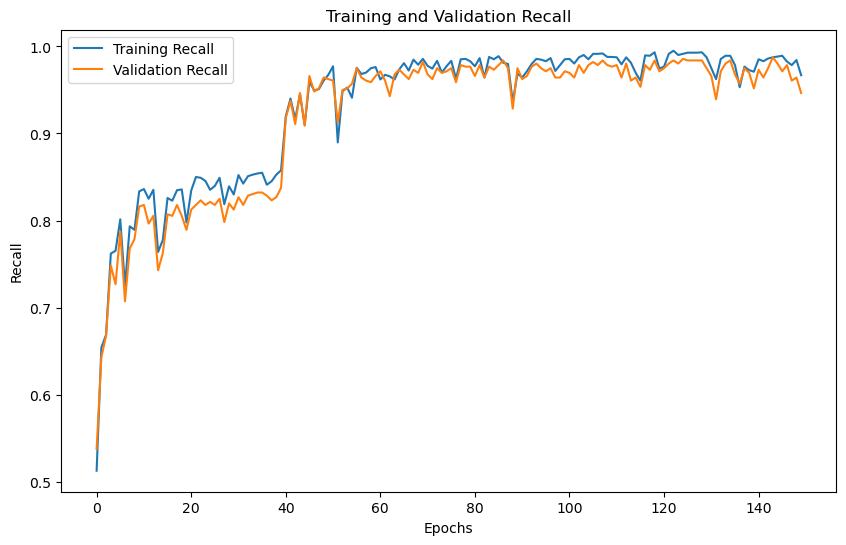

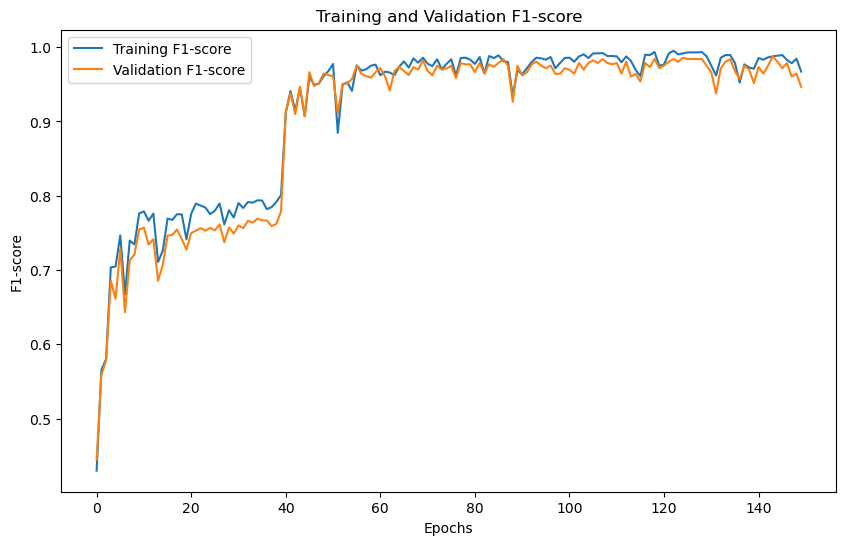

'Model Training and Evaluation Successfully completed'

In [21]:
train_model()

## Training and Validation 200 epochs

Enter no. of epochs 200
Epoch [1/200],
Training Loss: 1.8606, Training Accuracy: 0.4161, Training Precision:0.2970,Training Recall:0.4161,Training F1-Score:0.2964
Validation Loss: 1.7394, Validation Accuracy: 0.3875, Validation Precision:0.3018,Validation Recall:0.3875,Validation F1-Score:0.2733
Epoch [2/200],
Training Loss: 1.6277, Training Accuracy: 0.6143, Training Precision:0.5116,Training Recall:0.6143,Training F1-Score:0.5186
Validation Loss: 1.5670, Validation Accuracy: 0.6071, Validation Precision:0.5073,Validation Recall:0.6071,Validation F1-Score:0.5090
Epoch [3/200],
Training Loss: 1.5247, Training Accuracy: 0.6786, Training Precision:0.5008,Training Recall:0.6786,Training F1-Score:0.5722
Validation Loss: 1.5018, Validation Accuracy: 0.6625, Validation Precision:0.4822,Validation Recall:0.6625,Validation F1-Score:0.5548
Epoch [4/200],
Training Loss: 1.5624, Training Accuracy: 0.6482, Training Precision:0.4891,Training Recall:0.6482,Training F1-Score:0.5490
Validation Loss: 1

Epoch [31/200],
Training Loss: 1.3967, Training Accuracy: 0.8281, Training Precision:0.8396,Training Recall:0.8281,Training F1-Score:0.8082
Validation Loss: 1.3533, Validation Accuracy: 0.8268, Validation Precision:0.8418,Validation Recall:0.8268,Validation F1-Score:0.8027
Epoch [32/200],
Training Loss: 1.3227, Training Accuracy: 0.8821, Training Precision:0.8820,Training Recall:0.8821,Training F1-Score:0.8745
Validation Loss: 1.2990, Validation Accuracy: 0.8679, Validation Precision:0.8649,Validation Recall:0.8679,Validation F1-Score:0.8603
Epoch [33/200],
Training Loss: 1.2921, Training Accuracy: 0.8714, Training Precision:0.8753,Training Recall:0.8714,Training F1-Score:0.8639
Validation Loss: 1.3053, Validation Accuracy: 0.8625, Validation Precision:0.8640,Validation Recall:0.8625,Validation F1-Score:0.8514
Epoch [34/200],
Training Loss: 1.2755, Training Accuracy: 0.9464, Training Precision:0.9471,Training Recall:0.9464,Training F1-Score:0.9464
Validation Loss: 1.2169, Validation Ac

Epoch [61/200],
Training Loss: 1.1913, Training Accuracy: 0.9763, Training Precision:0.9766,Training Recall:0.9763,Training F1-Score:0.9763
Validation Loss: 1.2049, Validation Accuracy: 0.9607, Validation Precision:0.9617,Validation Recall:0.9607,Validation F1-Score:0.9609
Epoch [62/200],
Training Loss: 1.1883, Training Accuracy: 0.9839, Training Precision:0.9841,Training Recall:0.9839,Training F1-Score:0.9839
Validation Loss: 1.1957, Validation Accuracy: 0.9696, Validation Precision:0.9701,Validation Recall:0.9696,Validation F1-Score:0.9697
Epoch [63/200],
Training Loss: 1.1904, Training Accuracy: 0.9563, Training Precision:0.9607,Training Recall:0.9563,Training F1-Score:0.9566
Validation Loss: 1.2130, Validation Accuracy: 0.9518, Validation Precision:0.9528,Validation Recall:0.9518,Validation F1-Score:0.9517
Epoch [64/200],
Training Loss: 1.2060, Training Accuracy: 0.9437, Training Precision:0.9477,Training Recall:0.9437,Training F1-Score:0.9441
Validation Loss: 1.2260, Validation Ac

Epoch [91/200],
Training Loss: 1.1777, Training Accuracy: 0.9879, Training Precision:0.9881,Training Recall:0.9879,Training F1-Score:0.9878
Validation Loss: 1.1946, Validation Accuracy: 0.9714, Validation Precision:0.9719,Validation Recall:0.9714,Validation F1-Score:0.9714
Epoch [92/200],
Training Loss: 1.1760, Training Accuracy: 0.9915, Training Precision:0.9916,Training Recall:0.9915,Training F1-Score:0.9915
Validation Loss: 1.1851, Validation Accuracy: 0.9804, Validation Precision:0.9805,Validation Recall:0.9804,Validation F1-Score:0.9804
Epoch [93/200],
Training Loss: 1.1862, Training Accuracy: 0.9491, Training Precision:0.9547,Training Recall:0.9491,Training F1-Score:0.9479
Validation Loss: 1.2323, Validation Accuracy: 0.9321, Validation Precision:0.9403,Validation Recall:0.9321,Validation F1-Score:0.9300
Epoch [94/200],
Training Loss: 1.1841, Training Accuracy: 0.9862, Training Precision:0.9865,Training Recall:0.9862,Training F1-Score:0.9862
Validation Loss: 1.1933, Validation Ac

Epoch [121/200],
Training Loss: 1.1747, Training Accuracy: 0.9893, Training Precision:0.9895,Training Recall:0.9893,Training F1-Score:0.9893
Validation Loss: 1.1910, Validation Accuracy: 0.9750, Validation Precision:0.9754,Validation Recall:0.9750,Validation F1-Score:0.9750
Epoch [122/200],
Training Loss: 1.1758, Training Accuracy: 0.9942, Training Precision:0.9942,Training Recall:0.9942,Training F1-Score:0.9942
Validation Loss: 1.1885, Validation Accuracy: 0.9750, Validation Precision:0.9753,Validation Recall:0.9750,Validation F1-Score:0.9751
Epoch [123/200],
Training Loss: 1.1705, Training Accuracy: 0.9955, Training Precision:0.9956,Training Recall:0.9955,Training F1-Score:0.9955
Validation Loss: 1.1869, Validation Accuracy: 0.9768, Validation Precision:0.9768,Validation Recall:0.9768,Validation F1-Score:0.9768
Epoch [124/200],
Training Loss: 1.1710, Training Accuracy: 0.9964, Training Precision:0.9964,Training Recall:0.9964,Training F1-Score:0.9964
Validation Loss: 1.1863, Validatio

Epoch [151/200],
Training Loss: 1.1729, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.1858, Validation Accuracy: 0.9804, Validation Precision:0.9804,Validation Recall:0.9804,Validation F1-Score:0.9803
Epoch [152/200],
Training Loss: 1.1698, Training Accuracy: 0.9973, Training Precision:0.9973,Training Recall:0.9973,Training F1-Score:0.9973
Validation Loss: 1.1863, Validation Accuracy: 0.9786, Validation Precision:0.9789,Validation Recall:0.9786,Validation F1-Score:0.9785
Epoch [153/200],
Training Loss: 1.1690, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.1809, Validation Accuracy: 0.9857, Validation Precision:0.9859,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [154/200],
Training Loss: 1.1677, Training Accuracy: 0.9973, Training Precision:0.9973,Training Recall:0.9973,Training F1-Score:0.9973
Validation Loss: 1.1810, Validatio

Epoch [181/200],
Training Loss: 1.1827, Training Accuracy: 0.9839, Training Precision:0.9844,Training Recall:0.9839,Training F1-Score:0.9840
Validation Loss: 1.1814, Validation Accuracy: 0.9857, Validation Precision:0.9862,Validation Recall:0.9857,Validation F1-Score:0.9858
Epoch [182/200],
Training Loss: 1.1804, Training Accuracy: 0.9920, Training Precision:0.9920,Training Recall:0.9920,Training F1-Score:0.9920
Validation Loss: 1.1818, Validation Accuracy: 0.9839, Validation Precision:0.9845,Validation Recall:0.9839,Validation F1-Score:0.9840
Epoch [183/200],
Training Loss: 1.1752, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 1.1835, Validation Accuracy: 0.9821, Validation Precision:0.9821,Validation Recall:0.9821,Validation F1-Score:0.9821
Epoch [184/200],
Training Loss: 1.1690, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.1752, Validatio

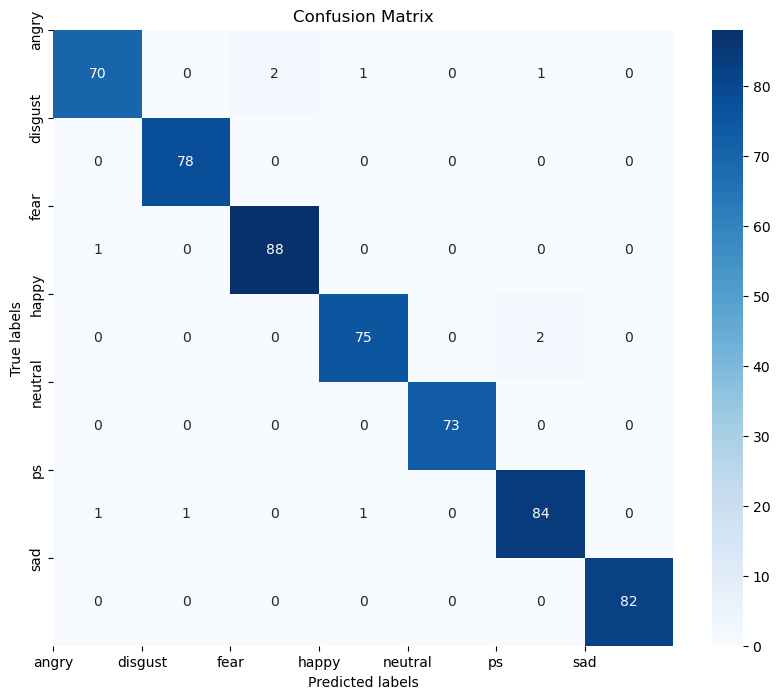

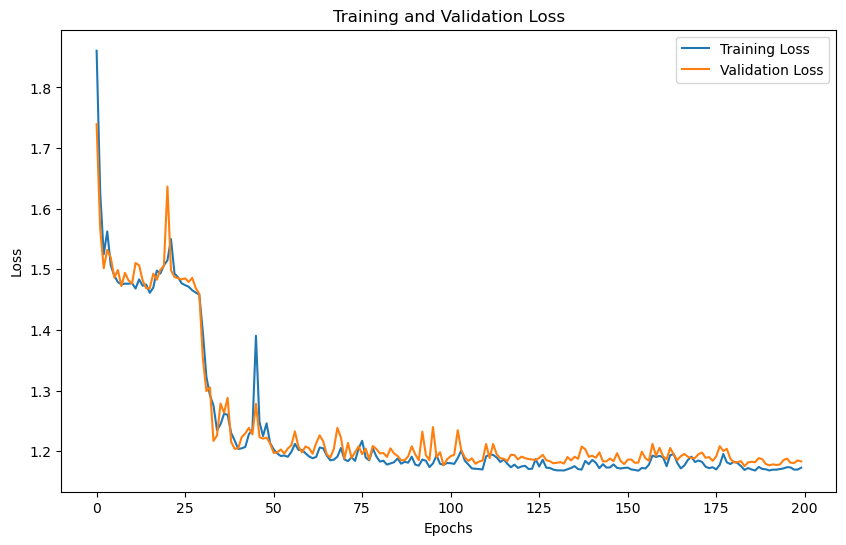

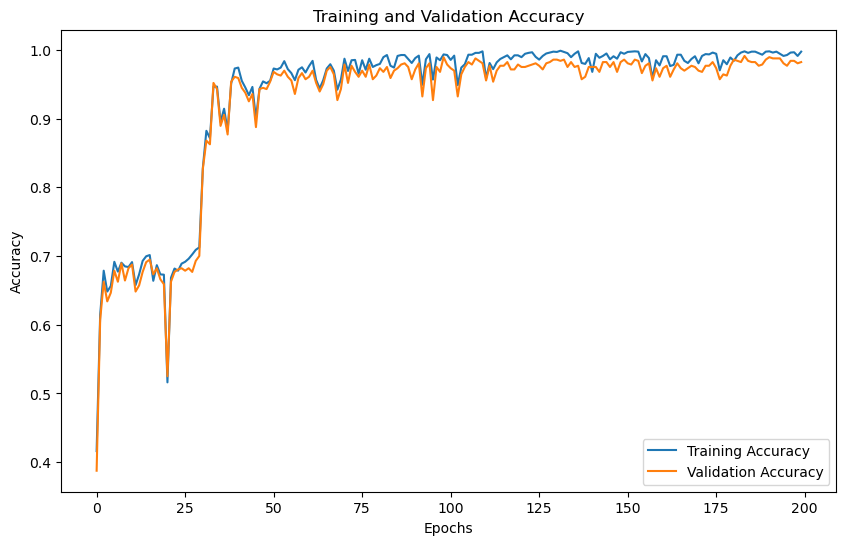

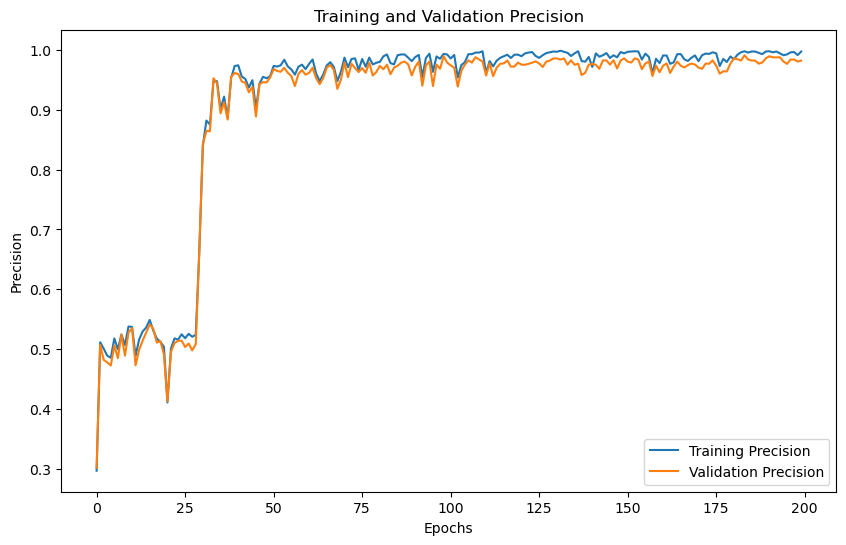

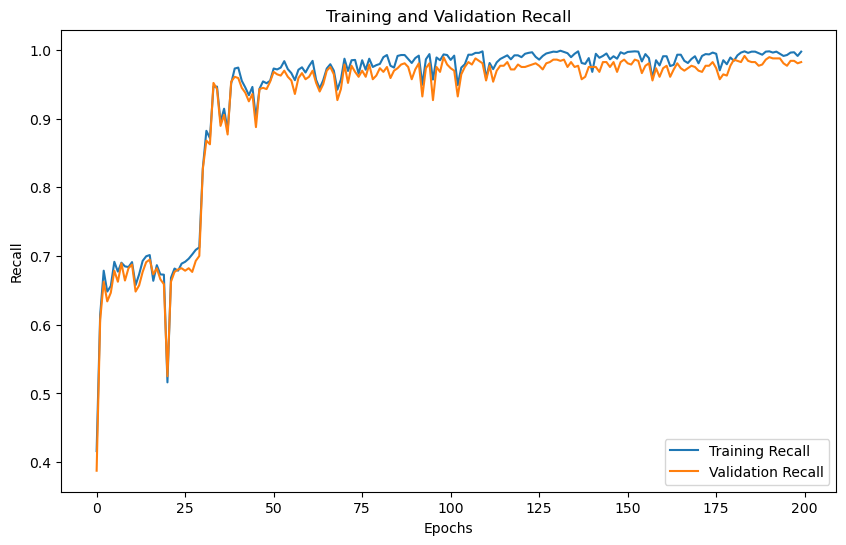

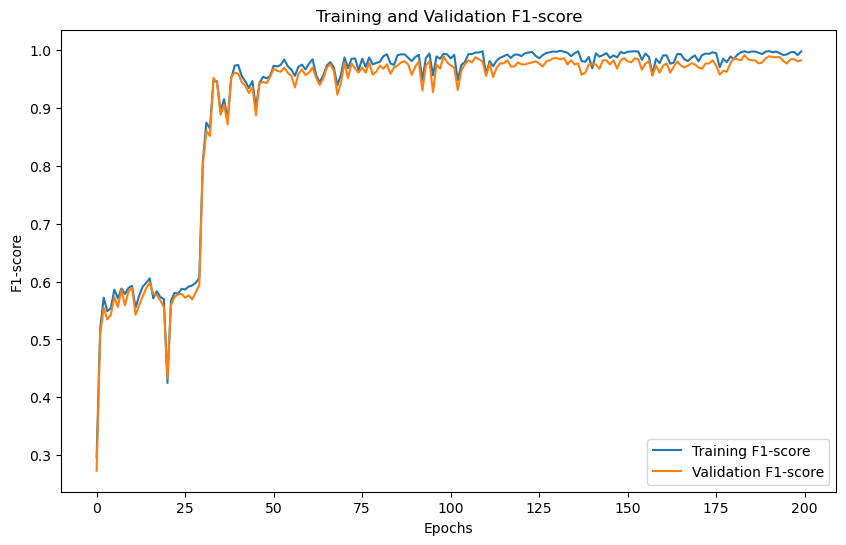

'Model Training and Evaluation Successfully completed'

In [21]:
train_model()